# Soal Latihan: Teknik Klastering (K-Means dan Hierarchical Clustering)
Nama: Auditya Merosya Putri | NIM: 24343001 

Notebook ini menjawab Soal 1 sampai 7.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

# Soal 1: Supervised vs Unsupervised Learning
(jawaban tertulis disajikan pada dokumen jawaban)

In [2]:
# Ilustrasi: data yang sama, dua pendekatan.
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
y_iris = iris.target

print('Supervised   : model dilatih dengan X (fitur) DAN y (label) -> memprediksi label data baru')
print('Unsupervised : model hanya melihat X -> menemukan kelompok alami; label baru dipakai untuk evaluasi (ARI)')
labels_km = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_iris)
print('\nCluster id hasil K-Means (10 data pertama):', labels_km[:10], '(angka id tidak bermakna sebagai nama kelas)')
print(pd.crosstab(pd.Series(y_iris, name='spesies asli'), pd.Series(labels_km, name='cluster K-Means')))

Supervised   : model dilatih dengan X (fitur) DAN y (label) -> memprediksi label data baru
Unsupervised : model hanya melihat X -> menemukan kelompok alami; label baru dipakai untuk evaluasi (ARI)

Cluster id hasil K-Means (10 data pertama): [1 1 1 1 1 1 1 1 1 1] (angka id tidak bermakna sebagai nama kelas)
cluster K-Means   0   1   2
spesies asli               
0                 0  50   0
1                39   0  11
2                14   0  36


# Soal 2: K-Means Manual (A(1,1), B(2,2), C(8,8), D(9,9); k=2; C1=A, C2=D)

In [3]:
P = np.array([[1, 1], [2, 2], [8, 8], [9, 9]], dtype=float)
nama = ['A', 'B', 'C', 'D']
centroid = P[[0, 3]].copy()                 # C1 = A, C2 = D

for it in range(1, 10):
    d = np.linalg.norm(P[:, None, :] - centroid[None, :, :], axis=2)   # jarak Euclidean ke tiap centroid
    cluster = d.argmin(axis=1)
    print(f'=== Iterasi {it} ===')
    print('Centroid  : C1 =', centroid[0].round(3), '| C2 =', centroid[1].round(3))
    print(pd.DataFrame({'d ke C1': d[:, 0].round(3), 'd ke C2': d[:, 1].round(3),
                        'Cluster': ['C' + str(c + 1) for c in cluster]}, index=nama))
    baru = np.array([P[cluster == j].mean(axis=0) for j in range(2)])
    print('Centroid baru: C1 =', baru[0].round(3), '| C2 =', baru[1].round(3), '\n')
    if np.allclose(baru, centroid):
        print('Centroid tidak berubah -> KONVERGEN pada iterasi', it)
        break
    centroid = baru

wcss = sum(((P[cluster == j] - centroid[j]) ** 2).sum() for j in range(2))
print('WCSS akhir =', round(wcss, 4))

=== Iterasi 1 ===
Centroid  : C1 = [1. 1.] | C2 = [9. 9.]
   d ke C1  d ke C2 Cluster
A    0.000   11.314      C1
B    1.414    9.899      C1
C    9.899    1.414      C2
D   11.314    0.000      C2
Centroid baru: C1 = [1.5 1.5] | C2 = [8.5 8.5] 

=== Iterasi 2 ===
Centroid  : C1 = [1.5 1.5] | C2 = [8.5 8.5]
   d ke C1  d ke C2 Cluster
A    0.707   10.607      C1
B    0.707    9.192      C1
C    9.192    0.707      C2
D   10.607    0.707      C2
Centroid baru: C1 = [1.5 1.5] | C2 = [8.5 8.5] 

Centroid tidak berubah -> KONVERGEN pada iterasi 2
WCSS akhir = 2.0


Label cluster : [0 0 1 1]
Centroid akhir: [[1.5, 1.5], [8.5, 8.5]]
Inertia (WCSS): 2.0


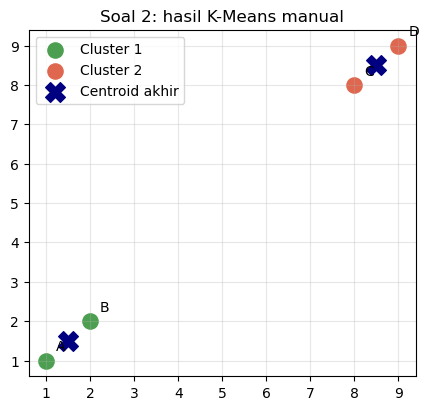

In [4]:
# Verifikasi dengan scikit-learn (init = centroid awal yang sama)
km = KMeans(n_clusters=2, init=P[[0, 3]], n_init=1).fit(P)
print('Label cluster :', km.labels_)
print('Centroid akhir:', km.cluster_centers_.tolist())
print('Inertia (WCSS):', round(km.inertia_, 4))

plt.figure(figsize=(5, 4.5))
warna = ['#4c9f50', '#e0674f']
for j in range(2):
    plt.scatter(*P[km.labels_ == j].T, s=120, color=warna[j], label=f'Cluster {j+1}')
plt.scatter(*km.cluster_centers_.T, marker='X', s=200, color='navy', label='Centroid akhir')
for n, (x, y) in zip(nama, P):
    plt.annotate(n, (x, y), textcoords='offset points', xytext=(7, 7))
plt.legend(); plt.grid(alpha=.3); plt.title('Soal 2: hasil K-Means manual')
plt.savefig('kl_soal2.png', dpi=150, bbox_inches='tight'); plt.show()

# Soal 3: Hierarchical Clustering Manual (complete linkage)

In [5]:
# Matriks jarak awal
D = np.array([[0, 2, 9, 10],
              [2, 0, 7, 8],
              [9, 7, 0, 3],
              [10, 8, 3, 0]], dtype=float)
print(pd.DataFrame(D, index=['P1', 'P2', 'P3', 'P4'], columns=['P1', 'P2', 'P3', 'P4']))

# Implementasi manual: gabungkan dua cluster dengan jarak complete linkage (maksimum antar anggota) terkecil
clusters = [[0], [1], [2], [3]]
nama_p = lambda c: '{' + ','.join(f'P{i+1}' for i in c) + '}'
def dist(a, b):
    return max(D[i, j] for i in a for j in b)          # complete linkage

langkah = 0
while len(clusters) > 1:
    pasangan = [(dist(clusters[i], clusters[j]), i, j) for i in range(len(clusters)) for j in range(i + 1, len(clusters))]
    d, i, j = min(pasangan)
    langkah += 1
    print(f'Langkah {langkah}: gabung {nama_p(clusters[i])} dan {nama_p(clusters[j])} pada jarak {d:g}')
    gabung = clusters[i] + clusters[j]
    clusters = [c for k, c in enumerate(clusters) if k not in (i, j)] + [gabung]
    if len(clusters) > 1:
        print('   jarak ke cluster lain:', {nama_p(c): float(dist(gabung, c)) for c in clusters if c is not gabung})

      P1   P2   P3    P4
P1   0.0  2.0  9.0  10.0
P2   2.0  0.0  7.0   8.0
P3   9.0  7.0  0.0   3.0
P4  10.0  8.0  3.0   0.0
Langkah 1: gabung {P1} dan {P2} pada jarak 2
   jarak ke cluster lain: {'{P3}': 9.0, '{P4}': 10.0}
Langkah 2: gabung {P3} dan {P4} pada jarak 3
   jarak ke cluster lain: {'{P1,P2}': 10.0}
Langkah 3: gabung {P1,P2} dan {P3,P4} pada jarak 10


   cluster_a  cluster_b  jarak  ukuran
0          0          1    2.0       2
1          2          3    3.0       2
2          4          5   10.0       4


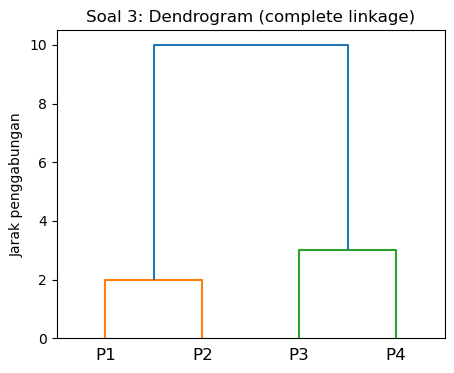

In [6]:
# Verifikasi dengan scipy
Z = linkage(squareform(D), method='complete')
print(pd.DataFrame(Z, columns=['cluster_a', 'cluster_b', 'jarak', 'ukuran']).astype({'cluster_a': int, 'cluster_b': int, 'ukuran': int}))

plt.figure(figsize=(5, 4))
dendrogram(Z, labels=['P1', 'P2', 'P3', 'P4'])
plt.title('Soal 3: Dendrogram (complete linkage)'); plt.ylabel('Jarak penggabungan')
plt.savefig('kl_soal3.png', dpi=150, bbox_inches='tight'); plt.show()

# Soal 4: Mengapa Elbow Tidak Sekadar Mencari WCSS Terkecil?

 k  WCSS  Penurunan dari k sebelumnya  Penurunan (%)
 1 600.0                          NaN            NaN
 2 222.4                        377.6           62.9
 3 139.8                         82.6           37.1
 4 114.1                         25.7           18.4
 5  90.9                         23.2           20.3
 6  81.5                          9.4           10.3
 7  72.6                          8.9           10.9
 8  62.5                         10.1           13.9
 9  55.1                          7.4           11.8
10  47.4                          7.7           14.0

WCSS pada 10 data dengan k=10 : 0.0


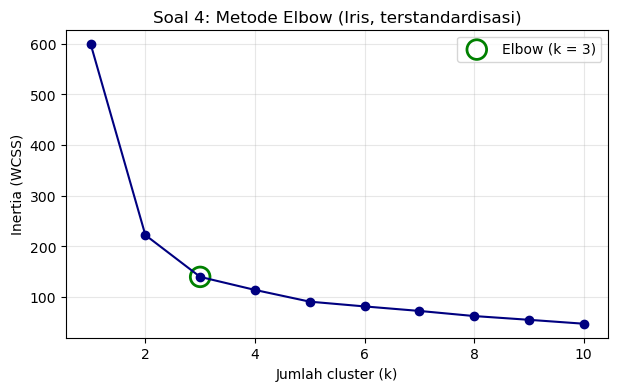

In [7]:
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_iris).inertia_ for k in range(1, 11)]
tabel = pd.DataFrame({'k': range(1, 11), 'WCSS': np.round(inertias, 1)})
tabel['Penurunan dari k sebelumnya'] = tabel['WCSS'].diff().abs().round(1)
tabel['Penurunan (%)'] = (tabel['WCSS'].pct_change().abs() * 100).round(1)
print(tabel.to_string(index=False))

# Bukti: WCSS = 0 jika k = jumlah data
kecil = X_iris[:10]
print('\nWCSS pada 10 data dengan k=10 :', round(KMeans(n_clusters=10, random_state=0, n_init=10).fit(kecil).inertia_, 6))

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertias, marker='o', color='navy')
plt.scatter(3, inertias[2], s=200, facecolors='none', edgecolors='green', linewidths=2, label='Elbow (k = 3)')
plt.xlabel('Jumlah cluster (k)'); plt.ylabel('Inertia (WCSS)'); plt.legend(); plt.grid(alpha=.3)
plt.title('Soal 4: Metode Elbow (Iris, terstandardisasi)')
plt.savefig('kl_soal4_elbow.png', dpi=150, bbox_inches='tight'); plt.show()

# Soal 5: Single Linkage, Silhouette Tinggi tetapi ARI Rendah

 linkage  Silhouette   ARI Ukuran cluster (besar ke kecil)
    ward       0.447 0.615                    [71, 49, 30]
complete       0.450 0.573                    [77, 49, 24]
 average       0.480 0.562                     [97, 50, 3]
  single       0.505 0.558                    [100, 49, 1]


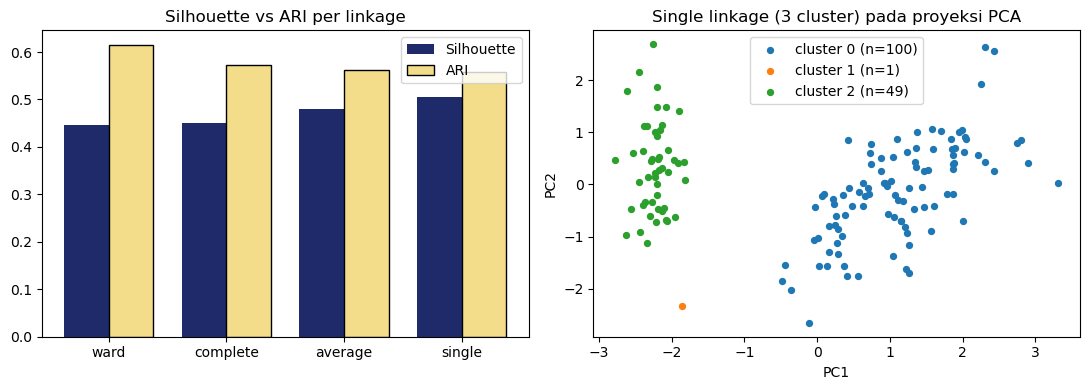


cluster single   0  1   2
spesies asli             
0                0  1  49
1               50  0   0
2               50  0   0


In [8]:
hasil = []
ukuran = {}
for link in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X_iris)
    hasil.append({'linkage': link, 'Silhouette': round(silhouette_score(X_iris, lab), 3),
                  'ARI': round(adjusted_rand_score(y_iris, lab), 3)})
    ukuran[link] = sorted(np.bincount(lab), reverse=True)
tab_link = pd.DataFrame(hasil)
tab_link['Ukuran cluster (besar ke kecil)'] = [ukuran[l] for l in tab_link['linkage']]
print(tab_link.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(4); w = 0.38
ax[0].bar(x - w/2, tab_link['Silhouette'], w, label='Silhouette', color='#1f2a6b')
ax[0].bar(x + w/2, tab_link['ARI'], w, label='ARI', color='#f3dd8a', edgecolor='black')
ax[0].set_xticks(x); ax[0].set_xticklabels(tab_link['linkage']); ax[0].legend(); ax[0].set_title('Silhouette vs ARI per linkage')
pca = PCA(n_components=2).fit(X_iris); Z2 = pca.transform(X_iris)
lab_single = AgglomerativeClustering(n_clusters=3, linkage='single').fit_predict(X_iris)
for c in np.unique(lab_single):
    ax[1].scatter(*Z2[lab_single == c].T, s=18, label=f'cluster {c} (n={int((lab_single == c).sum())})')
ax[1].legend(); ax[1].set_title('Single linkage (3 cluster) pada proyeksi PCA'); ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2')
plt.tight_layout(); plt.savefig('kl_soal5.png', dpi=150, bbox_inches='tight'); plt.show()

print()
print(pd.crosstab(pd.Series(y_iris, name='spesies asli'), pd.Series(lab_single, name='cluster single')))

# Soal 6: Dataset Lain (Wine): K-Means vs Hierarchical + Elbow

In [9]:
wine = load_wine()
Xw = StandardScaler().fit_transform(wine.data)
yw = wine.target
print('Ukuran data wine:', Xw.shape, '| jumlah kelas asli:', len(np.unique(yw)), '| data per kelas:', np.bincount(yw).tolist())

ks = range(1, 11)
inert_w = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xw).inertia_ for k in ks]
sil_w = {k: silhouette_score(Xw, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(Xw)) for k in range(2, 11)}
tab_w = pd.DataFrame({'k': list(ks), 'WCSS': np.round(inert_w, 1),
                      'Silhouette': [np.nan] + [round(sil_w[k], 3) for k in range(2, 11)]})
tab_w['Penurunan WCSS'] = tab_w['WCSS'].diff().abs().round(1)
print(tab_w.to_string(index=False))
print('\nk dengan Silhouette tertinggi:', max(sil_w, key=sil_w.get))

Ukuran data wine: (178, 13) | jumlah kelas asli: 3 | data per kelas: [59, 71, 48]
 k   WCSS  Silhouette  Penurunan WCSS
 1 2314.0         NaN             NaN
 2 1658.8       0.259           655.2
 3 1277.9       0.285           380.9
 4 1175.4       0.260           102.5
 5 1109.5       0.202            65.9
 6 1046.0       0.237            63.5
 7  981.6       0.204            64.4
 8  935.2       0.157            46.4
 9  889.9       0.150            45.3
10  845.9       0.144            44.0

k dengan Silhouette tertinggi: 3


 k   WCSS  Silhouette  Penurunan WCSS
 1 2314.0         NaN             NaN
 2 1658.8       0.259           655.2
 3 1277.9       0.285           380.9
 4 1175.4       0.260           102.5
 5 1109.5       0.202            65.9
 6 1046.0       0.237            63.5
 7  981.6       0.204            64.4
 8  935.2       0.157            46.4
 9  889.9       0.150            45.3
10  845.9       0.144            44.0

k dengan Silhouette tertinggi: 3


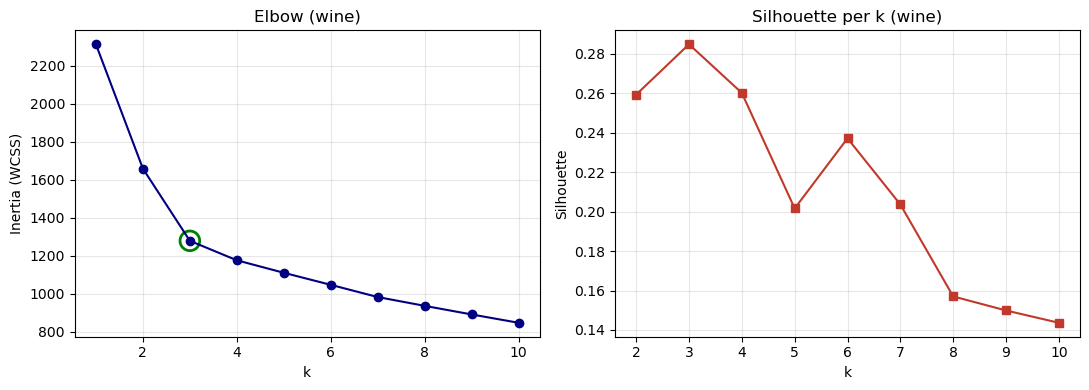

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inert_w, marker='o', color='navy'); ax[0].scatter(3, inert_w[2], s=200, facecolors='none', edgecolors='green', linewidths=2)
ax[0].set_xlabel('k'); ax[0].set_ylabel('Inertia (WCSS)'); ax[0].set_title('Elbow (wine)'); ax[0].grid(alpha=.3)
ax[1].plot(list(sil_w.keys()), list(sil_w.values()), marker='s', color='#c0392b')
ax[1].set_xlabel('k'); ax[1].set_ylabel('Silhouette'); ax[1].set_title('Silhouette per k (wine)'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig('kl_soal6_elbow.png', dpi=150, bbox_inches='tight'); plt.show()

In [11]:
km_w = KMeans(n_clusters=3, random_state=42, n_init=10).fit(Xw)
hi_w = AgglomerativeClustering(n_clusters=3, linkage='ward').fit(Xw)
perbandingan = pd.DataFrame({
    'Model': ['K-Means (k=3)', 'Hierarchical (Ward, 3 cluster)'],
    'Silhouette': [silhouette_score(Xw, km_w.labels_), silhouette_score(Xw, hi_w.labels_)],
    'ARI': [adjusted_rand_score(yw, km_w.labels_), adjusted_rand_score(yw, hi_w.labels_)],
}).round(4)
print(perbandingan.to_string(index=False))
print('\nKomposisi K-Means terhadap kelas asli:')
print(pd.crosstab(pd.Series(yw, name='kelas asli'), pd.Series(km_w.labels_, name='cluster K-Means')))
print('\nKomposisi Hierarchical terhadap kelas asli:')
print(pd.crosstab(pd.Series(yw, name='kelas asli'), pd.Series(hi_w.labels_, name='cluster Ward')))

                         Model  Silhouette    ARI
                 K-Means (k=3)      0.2849 0.8975
Hierarchical (Ward, 3 cluster)      0.2774 0.7899

Komposisi K-Means terhadap kelas asli:
cluster K-Means   0   1   2
kelas asli                 
0                 0   0  59
1                65   3   3
2                 0  48   0

Komposisi Hierarchical terhadap kelas asli:
cluster Ward   0   1   2
kelas asli              
0              0   0  59
1             58   8   5
2              0  48   0


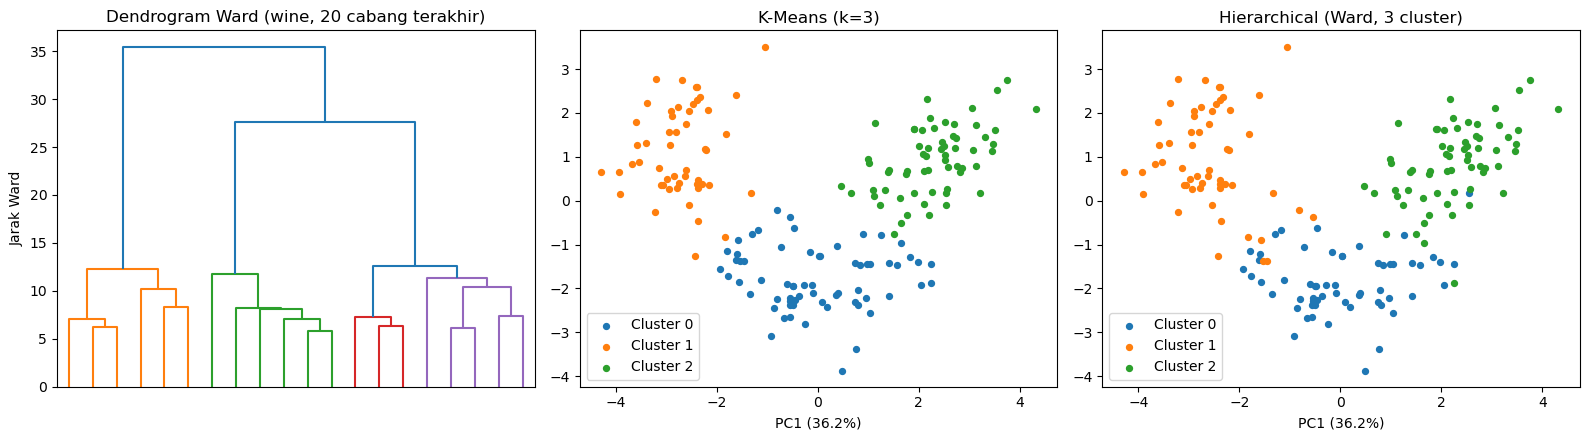

Variansi dijelaskan PC1+PC2:  55.4 %


In [14]:
Zw = linkage(Xw, method='ward')
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
dendrogram(Zw, truncate_mode='lastp', p=20, ax=ax[0], no_labels=True, color_threshold=Zw[-3, 2])
ax[0].set_title('Dendrogram Ward (wine, 20 cabang terakhir)'); ax[0].set_ylabel('Jarak Ward')
pc = PCA(n_components=2).fit(Xw); Zp = pc.transform(Xw)
for a, lab, judul in [(ax[1], km_w.labels_, 'K-Means (k=3)'), (ax[2], hi_w.labels_, 'Hierarchical (Ward, 3 cluster)')]:
    for c in range(3):
        a.scatter(*Zp[lab == c].T, s=18, label=f'Cluster {c}')
    a.set_title(judul); a.set_xlabel(f'PC1 ({pc.explained_variance_ratio_[0]*100:.1f}%)'); a.set_ylabel
    (f'PC2 ({pc.explained_variance_ratio_[1]*100:.1f}%)'); a.legend()
plt.tight_layout(); plt.savefig('kl_soal6_hasil.png', dpi=150, bbox_inches='tight'); plt.show()
print('Variansi dijelaskan PC1+PC2: ', round(pc.explained_variance_ratio_.sum() * 100, 1), '%')

# Soal 7: Clustering vs Klasifikasi saat Label Tersedia
(jawaban tertulis disajikan pada dokumen jawaban)

In [13]:
# Contoh pendukung: label historis (spesies) vs struktur yang ditemukan clustering pada Iris.
# Clustering tidak 'dipaksa' mengikuti label, sehingga bisa mengungkap struktur yang berbeda dari label.
print(pd.crosstab(pd.Series(y_iris, name='label historis (spesies)'), pd.Series(labels_km, name='cluster K-Means')))
print('\nARI K-Means vs label:', round(adjusted_rand_score(y_iris, labels_km), 4),
      '-> kecocokan bagus tetapi tidak sempurna: versicolor dan virginica saling tumpang tindih')

cluster K-Means            0   1   2
label historis (spesies)            
0                          0  50   0
1                         39   0  11
2                         14   0  36

ARI K-Means vs label: 0.6201 -> kecocokan bagus tetapi tidak sempurna: versicolor dan virginica saling tumpang tindih
